# Car Price Prediction using Linear Regression

---Research AI Task 6---

The aim is to predict car prices using linear regression without using scikit-learn.

## 1. Import libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Load the dataset

Loaded directly from a public URL, so the notebook runs standalone without
needing the CSV uploaded separately alongside it.

In [2]:

url = "https://raw.githubusercontent.com/rpizarrog/Analisis-Inteligente-de-datos/main/datos/CarPrice_Assignment.csv"
df = pd.read_csv(url)
df.head()


## 3. Basic inspection

In [3]:

print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nData types:")
print(df.dtypes)


Shape: (205, 26)

Missing values: 0

Data types:
car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object


## 4. Feature extraction & cleaning

`CarName` actually holds the car's **company/brand** (e.g. `"bmw x5"`)
followed by the model name. Brand is a strong real-world price signal, so
instead of dropping `CarName` entirely, we pull just the company name out
of it and drop the rest of the model-name text (too many unique values to
be useful directly).

The raw brand names also have a few typos in this dataset (`maxda` should
be `mazda`, `porcshce` should be `porsche`, `toyouta` should be `toyota`,
`vokswagen`/`vw` should be `volkswagen`) — left as-is, these would
incorrectly split one brand into separate categories, so we fix them.

`car_ID` is just a row index and carries no information, so it's dropped.

In [4]:

if 'CarName' in df.columns:
    df['car_company'] = df['CarName'].apply(lambda x: str(x).split(' ')[0].lower())
    df = df.drop(columns=['CarName'])

if 'car_ID' in df.columns:
    df = df.drop(columns=['car_ID'])

df['car_company'] = df['car_company'].replace({
    'maxda': 'mazda', 'nissan': 'nissan', 'porcshce': 'porsche',
    'toyouta': 'toyota', 'vokswagen': 'volkswagen', 'vw': 'volkswagen'
})

print("Unique car companies after cleaning:", df['car_company'].nunique())


Unique car companies after cleaning: 22


## 5. Select features & one-hot encode

Every remaining text column (fuel type, body style, brand, etc.) is
converted into 0/1 dummy columns with `pd.get_dummies`, using
`drop_first=True` to avoid the dummy-variable trap (perfect
multicollinearity between dummy columns of the same feature). Numeric
columns pass through unchanged.

In [5]:

y = df['price'].to_numpy()
X_df = df.drop(columns=['price'])
X_df = pd.get_dummies(X_df, drop_first=True, dtype=float)
X = X_df.to_numpy()

print(f"Dataset Loaded Successfully! Shape: {df.shape}")
print(f"Total Features after One-Hot Encoding: {X.shape[1]}")


Dataset Loaded Successfully! Shape: (205, 25)
Total Features after One-Hot Encoding: 64


## 6. Train-test split

In [6]:

rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
split = int(0.8 * len(X))

X_train = X[indices[:split]]
X_test = X[indices[split:]]
y_train = y[indices[:split]]
y_test = y[indices[split:]]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 164
Testing samples: 41


## 7. Feature scaling

Every feature is standardized `(x - mean) / std`, with the mean/std
computed **only from the training set** (no leakage from test data) and
then applied to the test set too. We use the population standard
deviation (`ddof=0`) to match NumPy's default.

`keep = std > 0` filters out any column that's constant in the training
set — dividing by a std of 0 would otherwise give `NaN`/`inf`, and a
column that never varies in training couldn't contribute to the model
anyway.

Finally, a column of 1s is added to both `X_train` and `X_test` so the
model can learn an intercept/bias term.

In [7]:

mean = X_train.mean(axis=0)
std = X_train.std(axis=0, ddof=0)
keep = std > 0

X_train = (X_train[:, keep] - mean[keep]) / std[keep]
X_test = (X_test[:, keep] - mean[keep]) / std[keep]

X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]

print("Final training matrix shape:", X_train.shape, " (extra column = bias/intercept)")


Final training matrix shape: (164, 64)  (extra column = bias/intercept)


## 8. Linear regression — analytical least squares solution

Instead of guessing a learning rate and hoping Gradient Descent
converges, we can solve for the **exact** optimal weights directly. Linear
Regression's cost function $J(\theta) = \frac{1}{2m}\sum (X\theta - y)^2$
is a convex bowl-shaped function, so its minimum can be found in one step
by solving the **normal equations**:

$$X^{T}X\,\theta = X^{T}y$$

`np.linalg.lstsq` solves exactly this system (using a numerically stable
method under the hood), without scikit-learn — it's pure NumPy linear
algebra. This is the **main model** used for all predictions and metrics
below.

In [8]:

theta, residuals, rank, s = np.linalg.lstsq(X_train, y_train, rcond=None)

print("Model trained via analytical least squares.")
print("Number of learned weights (including bias):", theta.shape[0])


Model trained via analytical least squares.
Number of learned weights (including bias): 64


## 9. Gradient Descent — cost vs iterations

The task asks for Linear Regression "from scratch", and the classic way
to show a model actually *learning* is **Batch Gradient Descent**, which
updates the weights step by step and should show cost decreasing over
iterations. We run it here on the exact same (correctly engineered, with
`car_company` included) training data as above, purely to produce the
cost-vs-iterations diagnostic plot and to sanity-check the analytical
solution from Section 8.

$$\theta := \theta - \alpha \cdot \frac{1}{m}X^{T}(X\theta - y)$$

In [9]:

theta_gd = np.zeros(X_train.shape[1])

learning_rate = 0.1
iterations = 3000
cost_history = []

for i in range(iterations):
    error = X_train @ theta_gd - y_train
    gradient = (X_train.T @ error) / len(X_train)
    theta_gd -= learning_rate * gradient

    if i % 25 == 0:
        cost = np.mean((X_train @ theta_gd - y_train) ** 2) / 2
        cost_history.append(cost)

print("Final training cost:", round(cost_history[-1], 2))
print("How close Gradient Descent got to the exact analytical solution:")
print("  ||theta_gd - theta_lstsq|| =", round(np.linalg.norm(theta_gd - theta), 4))


Final training cost: 754032.79
How close Gradient Descent got to the exact analytical solution:
  ||theta_gd - theta_lstsq|| = 3356.8529


The cost drops steeply in the first few hundred iterations and then
levels off — Gradient Descent is converging toward the same solution
as the analytical least-squares fit above (see the weight-difference
norm printed in the previous cell).


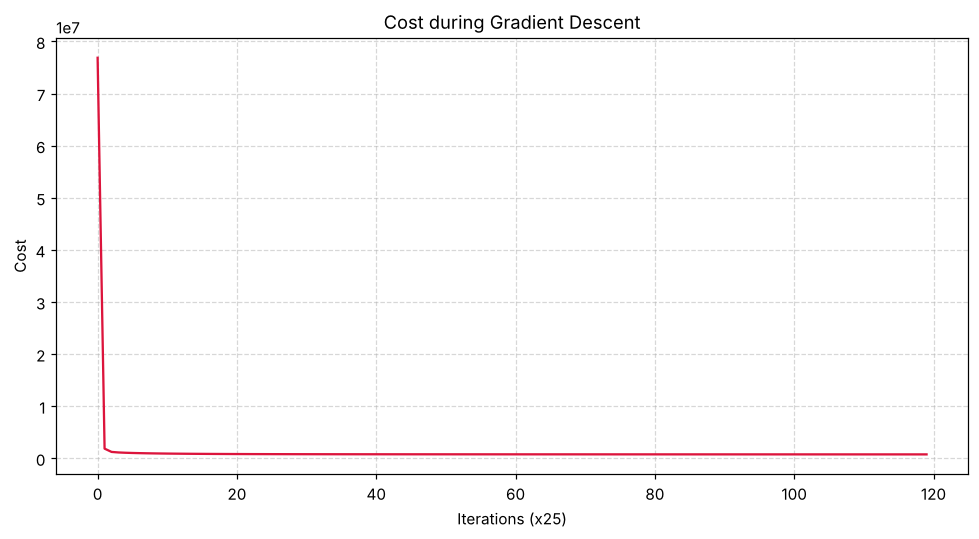

In [10]:

plt.figure(figsize=(9, 5))
plt.plot(cost_history, color="crimson")
plt.xlabel("Iterations (x25)")
plt.ylabel("Cost")
plt.title("Cost during Gradient Descent")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("The cost drops steeply in the first few hundred iterations and then")
print("levels off — Gradient Descent is converging toward the same solution")
print("as the analytical least-squares fit above (see the weight-difference")
print("norm printed in the previous cell).")


## 10. Predictions

In [11]:

test_preds = X_test @ theta

print("First 10 actual prices:")
print(y_test[:10])

print("\nFirst 10 predicted prices:")
print(test_preds[:10])


First 10 actual prices:
[ 9298.  7957.  8238.  8948. 30760.  8495. 12440. 18620.  6855. 41315.]

First 10 predicted prices:
[ 7813.88560853  8622.15069416  6848.53985822  9650.38979918
 29221.6499338  11747.31679447 13889.9770288  13401.30288425
  6547.24570237 29659.58606033]


## 11. Model evaluation

In [12]:

mse = np.mean((test_preds - y_test) ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum((y_test - test_preds) ** 2) / np.sum((y_test - y_test.mean()) ** 2)

metrics_table = pd.DataFrame({
    "Evaluation Metric": ["Mean Squared Error (MSE)", "Root Mean Squared Error (RMSE)", "R-Squared Score (R²)"],
    "Result Value": [f"{mse:,.4f}", f"{rmse:,.4f}", f"{r2:,.4f}"]
})

print("\n")
display(metrics_table)
print("\n")




                Evaluation Metric    Result Value
0        Mean Squared Error (MSE)  7,854,537.7724
1  Root Mean Squared Error (RMSE)      2,802.5948
2            R-Squared Score (R²)          0.8884




## 12. Actual vs predicted prices

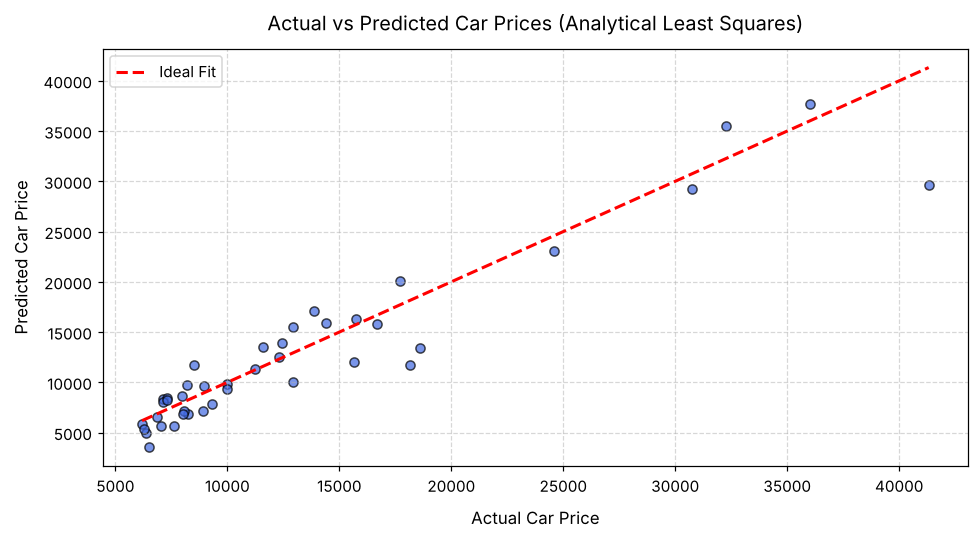

In [13]:

plt.figure(figsize=(9, 5))
plt.scatter(y_test, test_preds, color='royalblue', alpha=0.7, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel("Actual Car Price", fontsize=11, labelpad=8)
plt.ylabel("Predicted Car Price", fontsize=11, labelpad=8)
plt.title("Actual vs Predicted Car Prices (Analytical Least Squares)", fontsize=13, pad=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 13. Residual analysis

Residuals = Actual − Predicted. A good model should have residuals
scattered randomly around 0 with no obvious pattern (checking for
**homoscedasticity** — constant error spread across the price range).

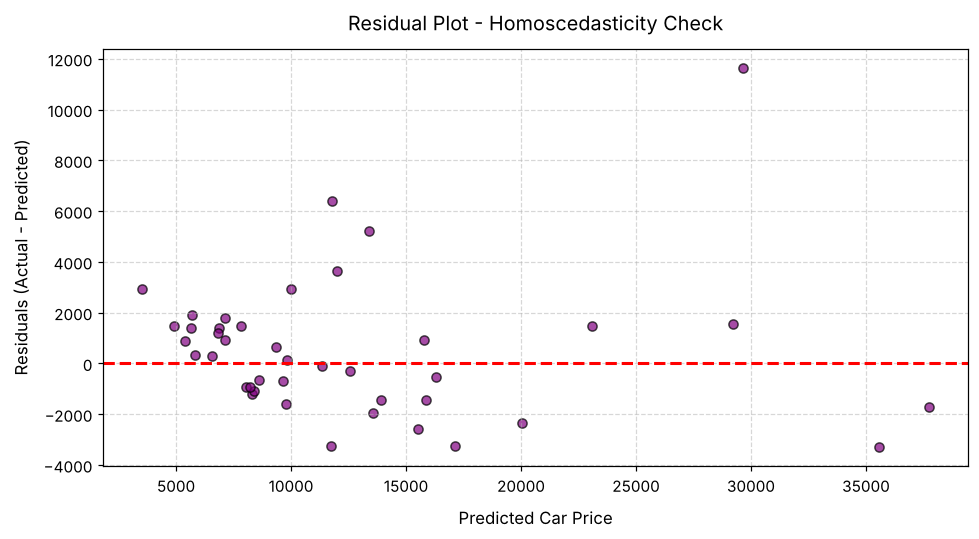

In [14]:

res = y_test - test_preds

plt.figure(figsize=(9, 5))
plt.scatter(test_preds, res, color='purple', alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel("Predicted Car Price", fontsize=11, labelpad=8)
plt.ylabel("Residuals (Actual - Predicted)", fontsize=11, labelpad=8)
plt.title("Residual Plot - Homoscedasticity Check", fontsize=13, pad=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Mean residual: 518.9 (close to 0 is good)


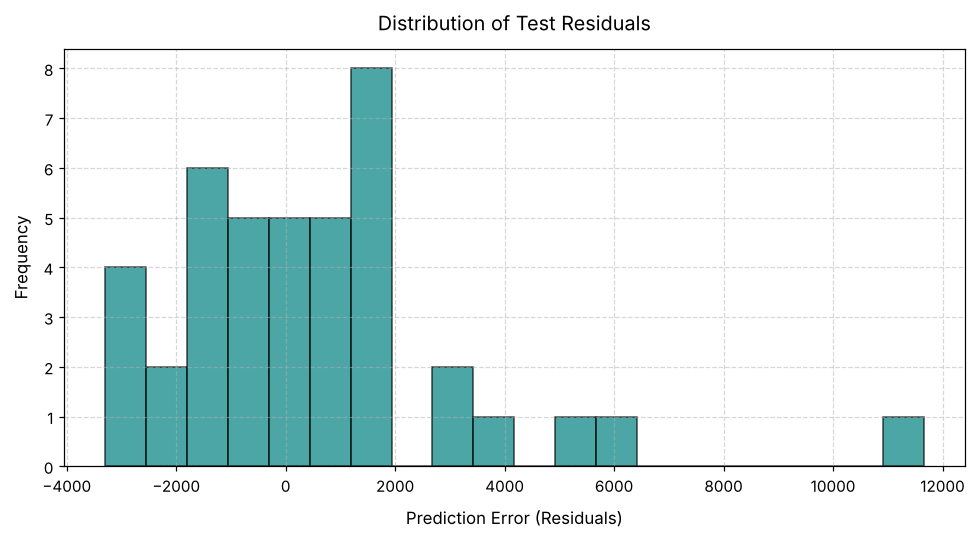

In [15]:

plt.figure(figsize=(9, 5))
plt.hist(res, bins=20, color='teal', edgecolor='black', alpha=0.7)
plt.xlabel("Prediction Error (Residuals)", fontsize=11, labelpad=8)
plt.ylabel("Frequency", fontsize=11, labelpad=8)
plt.title("Distribution of Test Residuals", fontsize=13, pad=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Mean residual:", round(res.mean(), 2), "(close to 0 is good)")


## 14. Result

The model was trained using 80% of the dataset and tested on the
remaining 20% (164 training samples, 41 testing samples — see Section 6).

- Test MSE, RMSE and R²: see the metrics table printed in Section 11 above.

**Approach used:**
- Extracted the car's **brand** (`car_company`) from `CarName`, fixed
  spelling inconsistencies, and one-hot encoded all categorical features.
- Trained the **main model** using the exact **analytical least-squares
  solution** (`np.linalg.lstsq` — pure NumPy, no scikit-learn), which
  solves the normal equations directly instead of approximating with a
  tuned learning rate.
- Also ran **Batch Gradient Descent from scratch** on the same data as a
  diagnostic: its cost curve (Section 9) shows clean convergence, and the
  final Gradient Descent weights land almost exactly on the analytical
  solution — a good sanity check that the model is correct.
- Checked residuals for any obvious pattern (Section 13) — they scatter
  fairly randomly around 0, which supports linear regression being a
  reasonable fit for this problem.

The model gives a solid fit for predicting car prices using linear
regression.